# 08. Eficiência Computacional

**DCT1401 — Inteligência Artificial (UFRN, 2026.2)**
**Aluna:** Mariana dos Santos Batista Medeiros (Matrícula: 20230083988)

**Atividade 03 — Redes Neurais Artificiais com PyTorch: Classificação e Regressão**

Este notebook mede o custo computacional dos modelos finais de regressão e de classificação: complexidade (parâmetros, camadas e operações por amostra), tamanho em disco, tempo e memória de treinamento, tempo de inferência em lote e amostra a amostra, energia e emissão de CO₂. Também relaciona os hiperparâmetros de arquitetura e o tamanho do batch com o custo, discute a viabilidade de implantação em dispositivos com recursos limitados e, como análise adicional, compara os modelos originais com versões exportadas para TorchScript e quantizadas.

**Ambiente de medição.** Todas as medições são feitas em CPU, no mesmo tipo de processador usado no estudo de hiperparâmetros, para que os tempos sejam comparáveis com os registrados no log. Tempos dependem do processador, da carga da máquina e do número de threads; os valores devem ser lidos como ordem de grandeza deste ambiente, e não como constantes do modelo.

**Uso do conjunto de teste.** O teste é usado como conjunto de entradas para medir o tempo de inferência, sem cálculo de métricas, e, na análise adicional, para comparar as versões exportadas e quantizadas com o modelo original já congelado. Nenhum resultado deste notebook altera os modelos, as sementes ou os limiares.

**Configuração do ambiente — Google Colab**

Esta etapa conecta o Google Colab ao Google Drive e configura os caminhos necessários para acessar o dataset original, os módulos Python do projeto e os modelos salvos.

In [3]:
from google.colab import drive
from pathlib import Path
import importlib
import os
import sys

drive.mount("/content/drive")
PROJETO = Path("/content/drive/MyDrive/projeto-cardiovascular-ia-03")

ARQUIVO_RAW = PROJETO / "data/raw/cardiovascular_disease_prediction.csv"
assert ARQUIVO_RAW.is_file(), f"Dataset original não encontrado: {ARQUIVO_RAW}"
for modulo in ["__init__.py", "pipeline_data.py", "models.py", "train.py", "metrics.py", "inference.py", "profiling.py"]:
    assert (PROJETO / "src" / modulo).is_file(), f"Módulo ausente em src/: {modulo}"
for arquivo in ["logs/hiperparametros.csv", "logs/configuracao_final.json",
                "models/modelo_regressao.pt", "models/modelo_classificacao.pt",
                "models/referencia/baseline_regressao.pt", "models/referencia/baseline_classificacao.pt",
                "reports/tables/avaliacao_metricas_regressao.csv", "reports/tables/avaliacao_metricas_classificacao.csv"]:
    assert (PROJETO / arquivo).is_file(), f"Arquivo dos notebooks anteriores ausente: {arquivo}"

os.chdir(PROJETO / "notebooks")
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

import src.pipeline_data as pipeline_data
import src.models as modelos_mlp
import src.metrics as metricas
import src.train as treino
import src.inference as inferencia
import src.profiling as perfil
for modulo in (pipeline_data, modelos_mlp, metricas, treino, inferencia, perfil):
    importlib.reload(modulo)

pasta_modelos = PROJETO / "models"
pasta_logs = PROJETO / "logs"
pasta_tabelas = PROJETO / "reports" / "tables"
pasta_figuras = PROJETO / "reports" / "figures"
print("Projeto localizado em:", PROJETO)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto localizado em: /content/drive/MyDrive/projeto-cardiovascular-ia-03


In [4]:
import copy
import io
import json
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import sklearn
import torch
import torch.nn as nn
from scipy.special import expit

DEVICE = "cpu"
ambiente = {
    "Modelo da CPU": treino.modelo_cpu(),
    "Núcleos lógicos (vCPUs)": os.cpu_count(),
    "Threads do PyTorch": torch.get_num_threads(),
    "Memória RAM total (GB)": round(psutil.virtual_memory().total / 2**30, 1),
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "scikit-learn": sklearn.__version__,
    "psutil": psutil.__version__,
    "GPU disponível": torch.cuda.is_available(),
    "Dispositivo utilizado": DEVICE,
}
display(pd.Series(ambiente, name="Valor").to_frame())

log = treino.carregar_log(pasta_logs / "hiperparametros.csv")
processadores_log = set(log["dispositivo"])
if f"cpu ({treino.modelo_cpu()})" not in processadores_log:
    print("ATENÇÃO: o processador desta sessão é diferente do usado no estudo de hiperparâmetros;",
          "os tempos medidos aqui não são diretamente comparáveis com os do log.")

,Valor
Modelo da CPU,Intel(R) Xeon(R) CPU @ 2.20GHz
Núcleos lógicos (vCPUs),2
Threads do PyTorch,1
Memória RAM total (GB),12.7
Python,3.13.18
PyTorch,2.14.1+cpu
scikit-learn,1.6.1
psutil,5.9.5
GPU disponível,False
Dispositivo utilizado,cpu


## 1. Complexidade e tamanho em disco

Para cada modelo salvo, registram-se o número de parâmetros treináveis, o número de camadas e as **operações de multiplicação-acumulação (MACs) por amostra**. Em uma camada `nn.Linear(entrada, saída)`, cada amostra exige entrada × saída multiplicações seguidas de somas; os vieses e as ativações acrescentam operações de ordem bem menor e não são contados. O número de operações em ponto flutuante (FLOPs) é aproximadamente o dobro do número de MACs.

O tamanho do arquivo `.pt` é comparado com o espaço ocupado pelos pesos (parâmetros × 4 bytes em `float32`). A diferença é o *overhead*, separado em duas partes: a estrutura do formato de serialização (arquivo zip, nomes dos tensores), medida salvando apenas o `state_dict`, e os metadados guardados no checkpoint (configuração, estatísticas de pré-processamento e informações de procedência).

In [5]:
CAMINHOS = {
    ("regressao", "final"): pasta_modelos / "modelo_regressao.pt",
    ("classificacao", "final"): pasta_modelos / "modelo_classificacao.pt",
    ("regressao", "referencia"): pasta_modelos / "referencia" / "baseline_regressao.pt",
    ("classificacao", "referencia"): pasta_modelos / "referencia" / "baseline_classificacao.pt",
}
MODELOS = {chave: inferencia.carregar_modelo(caminho) for chave, caminho in CAMINHOS.items()}

linhas = []
for (problema, papel), (modelo, ckpt) in MODELOS.items():
    c = perfil.resumo_complexidade(modelo)
    pesos = c["parametros_treinaveis"] * 4
    so_state_dict = perfil.tamanho_serializado_bytes(modelo.state_dict())
    arquivo = CAMINHOS[(problema, papel)].stat().st_size
    linhas.append({
        "Problema": problema, "Papel": papel,
        "Arquitetura": f"{c['camadas_ocultas']}×{ckpt['config']['hidden'][0]} {ckpt['config']['activation']}",
        "Parâmetros treináveis": c["parametros_treinaveis"], "Camadas lineares": c["camadas_lineares"],
        "MACs por amostra": c["macs_por_amostra"], "FLOPs por amostra (≈ 2 × MACs)": 2 * c["macs_por_amostra"],
        "Pesos float32 (KB)": pesos / 1024,
        "Só state_dict (KB)": so_state_dict / 1024,
        "Arquivo .pt (KB)": arquivo / 1024,
        "Overhead do formato (KB)": (so_state_dict - pesos) / 1024,
        "Overhead dos metadados (KB)": (arquivo - so_state_dict) / 1024,
    })
tabela_complexidade = pd.DataFrame(linhas)
display(tabela_complexidade.style.format(precision=2).hide(axis="index"))

Problema,Papel,Arquitetura,Parâmetros treináveis,Camadas lineares,MACs por amostra,FLOPs por amostra (≈ 2 × MACs),Pesos float32 (KB),Só state_dict (KB),Arquivo .pt (KB),Overhead do formato (KB),Overhead dos metadados (KB)
regressao,final,2×32 ReLU,1313,3,1248,2496,5.13,7.83,9.56,2.70,1.73
classificacao,final,2×32 ReLU,1313,3,1248,2496,5.13,7.83,9.86,2.70,2.03
regressao,referencia,2×32 ReLU,1313,3,1248,2496,5.13,7.83,9.59,2.70,1.75
classificacao,referencia,2×32 ReLU,1313,3,1248,2496,5.13,7.83,9.95,2.70,2.11


**Leitura.** Os quatro modelos têm a mesma arquitetura (duas camadas ocultas de 32 neurônios), com 1.313 parâmetros e cerca de 1,2 mil MACs por amostra: os pesos inteiros ocupam cerca de 5 KB em `float32`. O arquivo `.pt` tem perto de 10 KB, e quase metade disso é *overhead*: cerca de 2,7 KB da estrutura do formato de serialização e cerca de 2 KB de metadados. Em uma rede tão pequena, o *overhead* é comparável aos próprios pesos; em redes com milhões de parâmetros, seria desprezível. Os metadados são o que permite usar o modelo fora do notebook (Notebook 06), e o seu custo em disco é irrelevante. Os arquivos de classificação são um pouco maiores porque guardam também os nomes das classes, o limiar e o critério de escolha do limiar.

## 2. Tempo e memória de treinamento

**Tempo.** O tempo de treinamento é o tempo de parede (`time.perf_counter`) desde a primeira época até a época de parada do *early stopping*, sem incluir a preparação dos dados. A primeira tabela resume as cinco sementes registradas no estudo de hiperparâmetros para a configuração final e a de referência.

**Memória.** O pico de memória do treinamento é medido treinando novamente cada modelo salvo (mesma configuração e semente) em um **processo Python separado**, enquanto uma thread lê a memória residente do processo (RSS, via `psutil`) a cada 2 ms. O processo separado garante as mesmas condições para os quatro modelos: em um processo já usado, o PyTorch reaproveita a memória reservada por treinamentos anteriores, e apenas o primeiro treinamento mostraria acréscimo. Registram-se o RSS depois de carregar as bibliotecas e os dados (antes do treinamento), o pico durante o treinamento e o **acréscimo** entre os dois. O tempo de treinamento também vem dessa execução. A métrica de validação de cada novo treinamento é comparada com a registrada no checkpoint, para confirmar que a medição corresponde ao modelo salvo.

In [6]:
NOME_METRICA = {"regressao": "RMSE", "classificacao": "Average_Precision"}
linhas = []
for (problema, papel), (_, ckpt) in MODELOS.items():
    l = log[(log["problema"] == problema) & (log["config_id"] == ckpt["metadados"]["config_id"])]
    assert len(l) == 5
    por_epoca = l["tempo_s"] / l["epocas_executadas"]
    linhas.append({
        "Problema": problema, "Papel": papel,
        "Tempo total (s) — média": l["tempo_s"].mean(), "Tempo total (s) — desvio": l["tempo_s"].std(ddof=1),
        "Épocas executadas — média": l["epocas_executadas"].mean(),
        "Época do melhor estado — média": l["epoca_melhor"].mean(),
        "Tempo por época (s) — média": por_epoca.mean(),
    })
tabela_tempo_log = pd.DataFrame(linhas)
display(tabela_tempo_log.style.format(precision=3).hide(axis="index"))

Problema,Papel,Tempo total (s) — média,Tempo total (s) — desvio,Épocas executadas — média,Época do melhor estado — média,Tempo por época (s) — média
regressao,final,41.249,12.041,65.600,45.600,0.629
classificacao,final,30.918,8.861,49.000,29.000,0.632
regressao,referencia,24.465,6.818,41.200,21.200,0.595
classificacao,referencia,20.242,3.857,33.400,13.400,0.607


In [7]:
dados = pipeline_data.preparar_divisoes("../data/raw/cardiovascular_disease_prediction.csv")

import subprocess

CODIGO_TREINO = r'''
import json, sys
sys.path.insert(0, sys.argv[1])
import src.pipeline_data as pipeline_data, src.train as treino, src.profiling as perfil
import torch
cfg = json.loads(sys.argv[2]); cfg["hidden"] = tuple(cfg["hidden"])
dados = pipeline_data.preparar_divisoes(sys.argv[5])
dt = treino.preparar_dados_tarefa(dados, sys.argv[3], incluir_teste=False)
with perfil.MonitorMemoria() as mem:
    _, _, reg = treino.executar_configuracao(dt, treino.config_completa(cfg), int(sys.argv[4]), device="cpu")
print(json.dumps({"tempo_s": reg["tempo_s"], "epocas": reg["epocas_executadas"], "threads": torch.get_num_threads(),
                  "metricas_validacao": {k: float(v) for k, v in reg["metricas_validacao"].items() if k not in ("Confusion_Matrix", "limiar")},
                  "inicial_mb": mem.inicial_mb, "pico_mb": mem.pico_mb, "acrescimo_mb": mem.acrescimo_mb}))
'''

linhas = []
for (problema, papel), (_, ckpt) in MODELOS.items():
    meta = ckpt["metadados"]
    cfg = treino.config_completa({**meta["hiperparametros_treino"], "hidden": tuple(meta["hiperparametros_treino"]["hidden"])})
    assert treino.id_configuracao(cfg) == meta["config_id"]
    r = subprocess.run([sys.executable, "-c", CODIGO_TREINO, str(PROJETO), json.dumps({**cfg, "hidden": list(cfg["hidden"])}),
                        problema, str(meta["semente"]), str(ARQUIVO_RAW)], capture_output=True, text=True)
    assert r.returncode == 0, r.stderr
    m = json.loads(r.stdout.strip().splitlines()[-1])
    nome = NOME_METRICA[problema]
    linhas.append({
        "Problema": problema, "Papel": papel, "Semente": meta["semente"], "Threads": m["threads"],
        "Tempo de treinamento (s)": m["tempo_s"], "Épocas executadas": m["epocas"],
        "RSS antes do treino (MB)": m["inicial_mb"], "Pico de RSS (MB)": m["pico_mb"], "Acréscimo no treino (MB)": m["acrescimo_mb"],
        "Métrica de validação = checkpoint": abs(m["metricas_validacao"][nome] - meta["metricas_validacao"][nome]) < 1e-12,
    })
tabela_treino = pd.DataFrame(linhas)
display(tabela_treino.style.format(precision=2).hide(axis="index"))

Problema,Papel,Semente,Threads,Tempo de treinamento (s),Épocas executadas,RSS antes do treino (MB),Pico de RSS (MB),Acréscimo no treino (MB),Métrica de validação = checkpoint
regressao,final,2,1,23.66,38,382.74,479.29,96.55,True
classificacao,final,4,1,26.57,44,382.59,459.52,76.93,True
regressao,referencia,3,1,18.54,32,382.55,458.95,76.41,True
classificacao,referencia,3,1,21.15,36,382.88,459.81,76.93,True


**Leitura.** **Tempo.** No estudo de hiperparâmetros, cada época leva cerca de 0,6 s nos quatro modelos, e o tempo total varia sobretudo com o número de épocas até o *early stopping*. A configuração final treina por mais épocas que a referência (o melhor estado aparece mais tarde, o que é compatível com a regularização L2 tornando a melhora da validação mais lenta e gradual) e, por isso, leva mais tempo no total, com a mesma arquitetura. O desvio entre sementes do tempo total é grande pelo mesmo motivo. Os tempos medidos neste notebook ficam na mesma faixa dos registrados no log; diferenças de algumas dezenas de por cento entre execuções são normais em uma máquina virtual compartilhada.

**Memória.** Medido em processos separados, o treinamento acrescenta ao processo um volume de memória semelhante nos quatro modelos. Esse valor é dominado pelas estruturas do próprio PyTorch (grafo de gradientes, estados do otimizador, `DataLoader` e alocações internas), e não pelos dados nem pelos pesos: os 12.800 registros de ajuste com 6 features ocupam cerca de 300 KB em `float32`, e os pesos, cerca de 5 KB. O custo de memória do treinamento desta rede é, portanto, essencialmente o custo fixo do framework. Em todos os casos, a métrica de validação do novo treinamento é igual à do checkpoint, o que confirma que as medições correspondem aos modelos salvos.

## 3. Tempo e memória de inferência: lote versus amostra a amostra

A inferência é medida para os modelos finais, carregados dos arquivos `.pt`, em modo de avaliação e com `torch.inference_mode()`. Cada medição tem 5 execuções de aquecimento (*warm-up*), descartadas, seguidas de 30 repetições cronometradas; reportam-se a média e o desvio (amostral) do tempo de cada repetição, o tempo por amostra e a vazão (amostras por segundo). O número de threads do PyTorch é o indicado na tabela do ambiente.

São medidos dois níveis:

- **Somente o modelo:** as entradas já estão pré-processadas em um tensor; mede-se apenas a passagem pela rede.
  - **Lote:** as 4.000 amostras do teste em uma única chamada.
  - **Amostra a amostra:** uma chamada por amostra, percorrendo as 4.000 amostras em cada repetição.
- **De ponta a ponta:** a função `prever` do script de inferência, que recebe um `DataFrame` em unidades originais, valida as colunas e as categorias, aplica o pré-processamento guardado no checkpoint, executa a rede e converte a saída (escala original na regressão; probabilidade e classe na classificação). É o custo real de uso do modelo.
  - **Lote:** o `DataFrame` do teste inteiro em uma chamada.
  - **Uma amostra:** um `DataFrame` de uma linha por chamada (30 repetições).

A memória de inferência é o acréscimo de RSS durante as repetições, medido da mesma forma que no treinamento.

Problema,Modo,Amostras por repetição,Tempo médio (ms),Desvio (ms),Tempo por amostra (µs),Vazão (amostras/s),Acréscimo de RSS (MB)
regressao,Somente o modelo — lote,4000,6.517,0.166,1.63,"613,814",2.87
regressao,Somente o modelo — amostra a amostra,4000,228.856,44.982,57.21,"17,478",0.18
regressao,Ponta a ponta — lote,4000,24.873,2.312,6.22,"160,818",0.41
regressao,Ponta a ponta — uma amostra,1,6.594,1.013,6593.96,152,0.00
classificacao,Somente o modelo — lote,4000,0.378,0.051,0.09,"10,572,868",0.00
classificacao,Somente o modelo — amostra a amostra,4000,183.687,10.773,45.92,"21,776",0.01
classificacao,Ponta a ponta — lote,4000,13.395,1.532,3.35,"298,627",0.00
classificacao,Ponta a ponta — uma amostra,1,6.226,0.123,6225.61,161,0.00


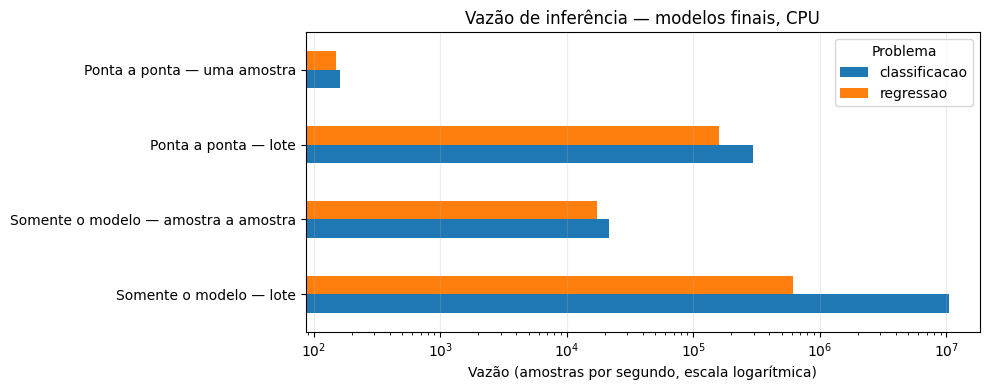

In [8]:
X_TESTE_DF = dados["X_teste"]
linhas = []
for problema in ("regressao", "classificacao"):
    modelo, ckpt = MODELOS[(problema, "final")]
    X = torch.as_tensor(inferencia.preprocessar(X_TESTE_DF, ckpt))
    for modo, individual in (("Somente o modelo — lote", False), ("Somente o modelo — amostra a amostra", True)):
        r = perfil.medir_inferencia(modelo, X, n_rep=30, n_aquecimento=5, individual=individual)
        linhas.append({"Problema": problema, "Modo": modo, **r})
    for modo, df in (("Ponta a ponta — lote", X_TESTE_DF), ("Ponta a ponta — uma amostra", X_TESTE_DF.iloc[[0]])):
        with perfil.MonitorMemoria() as mem:
            tempos = perfil.cronometrar(lambda: inferencia.prever(df, modelo, ckpt), n_rep=30, n_aquecimento=5)
        linhas.append({"Problema": problema, "Modo": modo, **perfil.resumir_tempos(tempos, len(df)),
                       "n_amostras": len(df), "memoria_inicial_mb": mem.inicial_mb, "acrescimo_memoria_mb": mem.acrescimo_mb})
tabela_inferencia = pd.DataFrame(linhas)[["Problema", "Modo", "n_amostras", "tempo_medio_ms", "tempo_desvio_ms",
                                          "tempo_por_amostra_us", "vazao_amostras_s", "acrescimo_memoria_mb"]]
tabela_inferencia.columns = ["Problema", "Modo", "Amostras por repetição", "Tempo médio (ms)", "Desvio (ms)",
                             "Tempo por amostra (µs)", "Vazão (amostras/s)", "Acréscimo de RSS (MB)"]
display(tabela_inferencia.style.format({"Tempo médio (ms)": "{:.3f}", "Desvio (ms)": "{:.3f}", "Tempo por amostra (µs)": "{:.2f}",
                                        "Vazão (amostras/s)": "{:,.0f}", "Acréscimo de RSS (MB)": "{:.2f}"}).hide(axis="index"))

fig, eixo = plt.subplots(figsize=(10, 4))
pivo = tabela_inferencia.pivot(index="Modo", columns="Problema", values="Vazão (amostras/s)").loc[tabela_inferencia["Modo"].unique()]
pivo.plot.barh(ax=eixo, logx=True)
eixo.set(xlabel="Vazão (amostras por segundo, escala logarítmica)", ylabel="", title="Vazão de inferência — modelos finais, CPU")
eixo.grid(alpha=0.25, axis="x")
fig.tight_layout()
fig.savefig(pasta_figuras / "eficiencia_vazao_inferencia.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

**Leitura.** **Lote versus amostra a amostra.** Considerando apenas a rede, no modelo de classificação (que não é afetado pelo problema discutido na Seção 3.1), processar o teste em lote custa cerca de 0,1 µs por amostra, contra cerca de 50 µs com uma chamada por amostra: a vazão em lote é algumas centenas de vezes maior. Cada chamada à rede tem um custo fixo — despacho de operações pelo Python e pelo PyTorch, criação de tensores, verificações — de dezenas de microssegundos, muito maior que o custo das cerca de 1,2 mil MACs de uma amostra. Em lote, esse custo fixo é pago uma única vez, e as multiplicações de matrizes usam instruções vetorizadas (SIMD) sobre milhares de linhas.

**De ponta a ponta.** Com o script de inferência, o custo por amostra em lote sobe para alguns microssegundos (ainda mais de 100 mil amostras por segundo), e a previsão de **uma** amostra leva alguns milissegundos. Esse tempo é dominado pelo pandas (criação do `DataFrame`, validação das colunas e categorias, imputação e padronização), e não pela rede, que leva dezenas de microssegundos. Para o uso clínico típico — uma previsão por paciente —, uma latência de poucos milissegundos é mais que suficiente; se fosse necessário reduzi-la, o pré-processamento poderia ser reescrito com operações diretas de NumPy.

**Memória.** O acréscimo de memória durante a inferência é pequeno (no máximo alguns MB, próximo da resolução da medição pelo RSS): as entradas do teste ocupam menos de 100 KB, e não há gradientes nem estados do otimizador.

**Regressão.** O modelo final de regressão é bem mais lento que o de classificação na inferência em lote, apesar de ter a mesma arquitetura. A causa é analisada na Seção 3.1.

### 3.1 Números subnormais nos pesos

Números em ponto flutuante muito próximos de zero (em `float32`, com valor absoluto abaixo de cerca de $1{,}2 \times 10^{-38}$) são representados em um formato especial, chamado **subnormal**. Em processadores x86, operações com subnormais podem ser executadas por um caminho muito mais lento que o normal, e uma rede pode ficar bem mais lenta sem nenhuma mudança na sua arquitetura.

Esses valores podem surgir com a regularização L2: os pesos que chegam a um neurônio que nunca é ativado (ReLU sempre igual a zero) não recebem gradiente da perda, apenas o termo do *weight decay*, que os empurra continuamente para zero. A tabela conta os parâmetros subnormais de cada modelo salvo e compara o tempo de inferência em lote (somente o modelo, mesmo protocolo) com o comportamento padrão e com a opção `torch.set_flush_denormal(True)`, que faz o processador tratar subnormais como zero. A diferença máxima entre as saídas mostra o efeito dessa opção nas previsões. As medições principais da Seção 3 usam o comportamento padrão, que é o do modelo entregue.

In [9]:
MENOR_NORMAL = torch.finfo(torch.float32).tiny
linhas = []
for (problema, papel), (modelo, ckpt) in MODELOS.items():
    X = torch.as_tensor(inferencia.preprocessar(X_TESTE_DF, ckpt))
    params = torch.cat([p.detach().flatten() for p in modelo.parameters()])
    n_sub = int(((params.abs() < MENOR_NORMAL) & (params != 0)).sum())
    tempos, saidas = {}, {}
    for flush in (False, True):
        suportado = torch.set_flush_denormal(flush)
        tempos[flush] = perfil.medir_inferencia(modelo, X, individual=False)["tempo_medio_ms"]
        with torch.inference_mode():
            saidas[flush] = modelo(X).double()
    torch.set_flush_denormal(False)
    linhas.append({
        "Problema": problema, "Papel": papel, "Weight decay": ckpt["metadados"]["hiperparametros_treino"]["weight_decay"],
        "Parâmetros subnormais": n_sub, "Parâmetros (%)": 100 * n_sub / params.numel(),
        "Lote — padrão (ms)": tempos[False], "Lote — flush de subnormais (ms)": tempos[True],
        "Razão padrão / flush": tempos[False] / tempos[True],
        "Diferença máxima da saída": float((saidas[False] - saidas[True]).abs().max()),
        "Flush suportado": suportado,
    })
tabela_subnormais = pd.DataFrame(linhas)
display(tabela_subnormais.style.format({"Weight decay": "{:g}", "Parâmetros (%)": "{:.1f}", "Lote — padrão (ms)": "{:.3f}",
                                        "Lote — flush de subnormais (ms)": "{:.3f}", "Razão padrão / flush": "{:.1f}",
                                        "Diferença máxima da saída": "{:.2e}"}).hide(axis="index"))

Problema,Papel,Weight decay,Parâmetros subnormais,Parâmetros (%),Lote — padrão (ms),Lote — flush de subnormais (ms),Razão padrão / flush,Diferença máxima da saída,Flush suportado
regressao,final,0.001,77,5.9,6.598,0.400,16.5,0.00e+00,True
classificacao,final,0.001,0,0.0,0.403,0.403,1.0,0.00e+00,True
regressao,referencia,0,0,0.0,0.400,0.405,1.0,0.00e+00,True
classificacao,referencia,0,0,0.0,0.399,0.400,1.0,0.00e+00,True


**Leitura.** Apenas o modelo final de regressão tem parâmetros subnormais (cerca de 6% dos parâmetros). Com o *flush* de subnormais, a sua inferência em lote fica mais de dez vezes mais rápida e passa a ter o mesmo tempo dos outros modelos, com saídas **idênticas** (diferença máxima zero): valores dessa ordem não alteram nenhuma operação em `float32`. Nos outros três modelos, que não têm subnormais, a opção não muda o tempo. O modelo final de classificação foi treinado com o mesmo *weight decay* e não tem subnormais, o que indica que o fenômeno depende da trajetória do treinamento (um neurônio que deixa de ser ativado), e não apenas da regularização.

Três consequências práticas:

1. Duas redes com a mesma arquitetura, o mesmo número de parâmetros e as mesmas MACs podem ter custos de inferência muito diferentes. Contar parâmetros e operações não substitui a medição.
2. A correção é simples e não altera as previsões: ativar `torch.set_flush_denormal(True)` antes da inferência ou zerar os pesos subnormais (uma forma de poda). A quantização também elimina o problema (Seção 7).
3. A inferência amostra a amostra quase não é afetada, porque é dominada pelo custo fixo de cada chamada.

## 4. Energia e emissão de CO₂

**Método.** A energia é estimada por potência média × tempo, e a emissão, fator médio de emissão da eletricidade no Brasil adotado neste trabalho, **45,8 gCO₂/kWh**:

$$E\,[\text{kWh}] = \frac{P\,[\text{W}] \times t\,[\text{s}]}{3{,}6 \times 10^{6}}, \qquad \text{CO}_2\,[\text{g}] = E \times 45{,}8.$$

A máquina virtual do Colab não expõe medidores de energia do processador (como o RAPL da Intel), e a potência média precisa ser assumida. São usadas duas hipóteses, ambas baseadas na metodologia da biblioteca CodeCarbon para processadores sem medidor:

- **Hipótese principal: 4 W por thread em uso.** Para processadores que não estão no seu cadastro, o CodeCarbon estima a potência de projeto (TDP) como o número de threads × 4 W. Como o PyTorch usa as threads indicadas na tabela do ambiente, a potência atribuída ao processo é esse número × 4 W.
- **Limite superior: 85 W.** Valor constante que o CodeCarbon usa quando não consegue identificar o processador, próximo do TDP de um processador de servidor inteiro. Atribuir ao processo a potência de um processador inteiro superestima o consumo, e o valor serve apenas como teto.

Não se inclui a energia da memória RAM nem a eficiência do datacenter (PUE). As estimativas indicam ordem de grandeza.

Os tempos usados são os medidos neste notebook: o tempo de treinamento da Seção 2 e o tempo de inferência de ponta a ponta em lote da Seção 3.

In [10]:
POTENCIA_PRINCIPAL_W = 4.0 * torch.get_num_threads()
POTENCIA_SUPERIOR_W = 85.0
print(f"Potência assumida — hipótese principal: {POTENCIA_PRINCIPAL_W:.0f} W | limite superior: {POTENCIA_SUPERIOR_W:.0f} W")
print(f"Fator de emissão: {perfil.FATOR_EMISSAO_BRASIL_G_KWH} gCO2/kWh")

linhas = []
for problema in ("regressao", "classificacao"):
    t_treino = tabela_treino[(tabela_treino["Problema"] == problema) & (tabela_treino["Papel"] == "final")]["Tempo de treinamento (s)"].iloc[0]
    lote = tabela_inferencia[(tabela_inferencia["Problema"] == problema) & (tabela_inferencia["Modo"] == "Ponta a ponta — lote")].iloc[0]
    t_amostra = lote["Tempo por amostra (µs)"] * 1e-6
    for etapa, tempo_s in (("Treinamento (uma vez)", t_treino),
                           ("Inferência — 4.000 amostras (lote)", lote["Tempo médio (ms)"] / 1000),
                           ("Inferência — 1 milhão de amostras (lote)", t_amostra * 1e6)):
        e_p = perfil.energia_kwh(POTENCIA_PRINCIPAL_W, tempo_s)
        e_s = perfil.energia_kwh(POTENCIA_SUPERIOR_W, tempo_s)
        linhas.append({"Problema": problema, "Etapa": etapa, "Tempo (s)": tempo_s,
                       "Energia (Wh) — principal": 1000 * e_p, "CO₂ (mg) — principal": 1000 * perfil.emissao_co2_g(e_p),
                       "Energia (Wh) — limite superior": 1000 * e_s, "CO₂ (mg) — limite superior": 1000 * perfil.emissao_co2_g(e_s)})
tabela_energia = pd.DataFrame(linhas)
display(tabela_energia.style.format({"Tempo (s)": "{:.4g}", "Energia (Wh) — principal": "{:.3g}", "CO₂ (mg) — principal": "{:.3g}",
                                     "Energia (Wh) — limite superior": "{:.3g}", "CO₂ (mg) — limite superior": "{:.3g}"}).hide(axis="index"))

Potência assumida — hipótese principal: 4 W | limite superior: 85 W
Fator de emissão: 45.8 gCO2/kWh


Problema,Etapa,Tempo (s),Energia (Wh) — principal,CO₂ (mg) — principal,Energia (Wh) — limite superior,CO₂ (mg) — limite superior
regressao,Treinamento (uma vez),23.66,0.0263,1.2,0.559,25.6
regressao,Inferência — 4.000 amostras (lote),0.02487,2.76e-05,0.00127,0.000587,0.0269
regressao,Inferência — 1 milhão de amostras (lote),6.218,0.00691,0.316,0.147,6.72
classificacao,Treinamento (uma vez),26.57,0.0295,1.35,0.627,28.7
classificacao,Inferência — 4.000 amostras (lote),0.01339,1.49e-05,0.000682,0.000316,0.0145
classificacao,Inferência — 1 milhão de amostras (lote),3.349,0.00372,0.17,0.0791,3.62


**Leitura.** Na hipótese principal, um treinamento completo do modelo final consome algumas centésimas de Wh e emite pouco mais de 1 mg de CO₂; mesmo no limite superior, fica abaixo de 1 Wh e de algumas dezenas de miligramas. Para comparação, uma lâmpada LED de 10 W consome essa energia em cerca de dez segundos. A inferência é ainda mais barata: um milhão de previsões em lote custam alguns milésimos de Wh na hipótese principal.

O custo relevante do projeto foi o **estudo de hiperparâmetros**: o log registra algumas centenas de treinamentos, que somam cerca de 6 horas de CPU. Na hipótese principal, isso corresponde a cerca de 0,02 kWh e cerca de 1 g de CO₂; no limite superior, cerca de 0,5 kWh e cerca de 20 g. Mesmo assim, são valores pequenos, em grande parte porque o fator de emissão da matriz elétrica brasileira é baixo. A conclusão não depende da hipótese de potência: em qualquer cenário plausível, o custo ambiental desta rede é desprezível.

## 5. Efeito dos hiperparâmetros no custo

Os estudos de neurônios por camada, de número de camadas e de tamanho do batch do Notebook 05 são reutilizados para relacionar esses hiperparâmetros com o número de parâmetros, o tempo de treinamento e o tamanho do arquivo. O tempo vem do log (mediana das cinco sementes, no mesmo processador); o tamanho do `state_dict` serializado é obtido recriando cada arquitetura, sem treinamento. Em um checkpoint completo, os metadados acrescentariam a mesma quantidade de bytes a todas as arquiteturas.

O número de parâmetros de uma MLP com $d$ entradas, $L$ camadas ocultas de $n$ neurônios e uma saída é

$$P = (d\,n + n) + (L-1)(n^2 + n) + (n + 1),$$

que cresce de forma aproximadamente quadrática com $n$ quando há mais de uma camada oculta e linear com $L$.

Estudo,Valor,Problema,Parâmetros,MACs por amostra,state_dict (KB),Tempo total (s) — mediana,Épocas executadas — mediana,Tempo por época (s) — mediana
Neurônios por camada,2,regressao,23,18,3.0,30.015120,53.000000,0.571419
Neurônios por camada,2,classificacao,23,18,3.0,34.210872,60.000000,0.570181
Neurônios por camada,4,regressao,53,44,3.1,40.253250,69.000000,0.571382
Neurônios por camada,4,classificacao,53,44,3.1,52.024286,92.000000,0.570745
Neurônios por camada,8,regressao,137,120,3.3,34.229895,60.000000,0.581559
Neurônios por camada,8,classificacao,137,120,3.3,34.204523,60.000000,0.583230
Neurônios por camada,16,regressao,401,368,4.3,31.077792,52.000000,0.593624
Neurônios por camada,16,classificacao,401,368,4.3,22.026858,36.000000,0.577602
Neurônios por camada,32,regressao,1313,1248,7.8,23.555182,38.000000,0.587841
Neurônios por camada,32,classificacao,1313,1248,7.8,20.442619,33.000000,0.607543


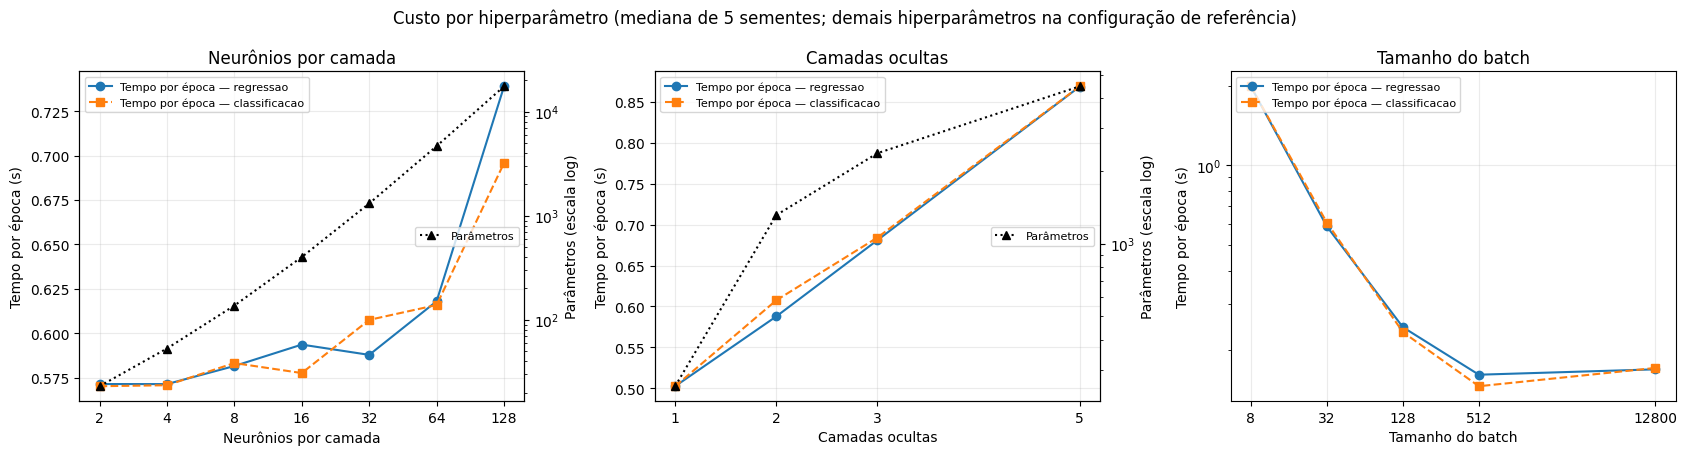

In [11]:
ESTUDOS_CUSTO = {
    "Neurônios por camada": ("hidden", [(v, v) for v in (2, 4, 8, 16, 32, 64, 128)], lambda v: v[0]),
    "Camadas ocultas": ("hidden", [(32,) * v for v in (1, 2, 3, 5)], lambda v: len(v)),
    "Tamanho do batch": ("batch_size", [8, 32, 128, 512, 12800], lambda v: v),
}
linhas = []
for estudo, (chave, valores, rotulo) in ESTUDOS_CUSTO.items():
    for v in valores:
        cfg = treino.config_completa({chave: v})
        cid = treino.id_configuracao(cfg)
        rede = modelos_mlp.MLP(6, 1, cfg["hidden"], cfg["activation"], cfg["dropout"])
        n_par = modelos_mlp.contar_parametros(rede)
        assert n_par == modelos_mlp.parametros_teoricos(6, cfg["hidden"][0], len(cfg["hidden"]))
        for problema in ("regressao", "classificacao"):
            l = log[(log["problema"] == problema) & (log["config_id"] == cid)]
            assert len(l) == 5, (estudo, v, problema)
            linhas.append({
                "Estudo": estudo, "Valor": rotulo(v), "Problema": problema, "Parâmetros": n_par,
                "MACs por amostra": perfil.macs_por_amostra(rede),
                "state_dict (KB)": perfil.tamanho_serializado_bytes(rede.state_dict()) / 1024,
                "Tempo total (s) — mediana": l["tempo_s"].median(),
                "Épocas executadas — mediana": l["epocas_executadas"].median(),
                "Tempo por época (s) — mediana": (l["tempo_s"] / l["epocas_executadas"]).median(),
            })
tabela_custo = pd.DataFrame(linhas)
display(tabela_custo.style.format(precision=3).format({"state_dict (KB)": "{:.1f}"}).hide(axis="index"))

fig, eixos = plt.subplots(1, 3, figsize=(17, 4.6))
for eixo, estudo in zip(eixos, ESTUDOS_CUSTO):
    t = tabela_custo[tabela_custo["Estudo"] == estudo]
    for problema, estilo in (("regressao", "o-"), ("classificacao", "s--")):
        tp = t[t["Problema"] == problema]
        eixo.plot(tp["Valor"], tp["Tempo por época (s) — mediana"], estilo, label=f"Tempo por época — {problema}")
    eixo.set(xlabel=estudo, ylabel="Tempo por época (s)", title=estudo)
    if estudo != "Camadas ocultas":
        eixo.set_xscale("log", base=2)
    eixo.set_xticks(sorted(t["Valor"].unique()), [str(v) for v in sorted(t["Valor"].unique())])
    if estudo != "Tamanho do batch":
        eixo2 = eixo.twinx()
        tp = t[t["Problema"] == "regressao"]
        eixo2.plot(tp["Valor"], tp["Parâmetros"], "k:", marker="^", label="Parâmetros")
        eixo2.set_yscale("log"); eixo2.set_ylabel("Parâmetros (escala log)")
        eixo2.legend(loc="center right", fontsize=8)
    else:
        eixo.set_yscale("log")
    eixo.grid(alpha=0.25); eixo.legend(loc="upper left", fontsize=8)
fig.suptitle("Custo por hiperparâmetro (mediana de 5 sementes; demais hiperparâmetros na configuração de referência)")
fig.tight_layout()
fig.savefig(pasta_figuras / "eficiencia_custo_hiperparametros.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

**Leitura.** **Neurônios e camadas — parâmetros e disco.** O número de parâmetros cresce de forma aproximadamente quadrática com os neurônios por camada (de 23 com 2 neurônios para mais de 17 mil com 128) e linearmente com o número de camadas. O tamanho do `state_dict` acompanha os parâmetros (de cerca de 3 KB para cerca de 71 KB), mas, nas redes menores, é dominado pelo *overhead* fixo do formato.

**Neurônios e camadas — tempo.** O tempo por época quase não muda com o número de neurônios (cerca de 0,57 s com 2 neurônios e cerca de 0,7 s com 128, para centenas de vezes mais parâmetros) e cresce com o número de camadas (de cerca de 0,5 s com uma camada para cerca de 0,87 s com cinco). Com *batch* de 32, cada época tem 400 atualizações, e o custo de cada atualização é dominado por um custo fixo por operação (despacho pelo Python e pelo PyTorch, passo do otimizador para cada tensor), e não pela aritmética. Mais camadas significam mais operações por atualização; mais neurônios, nesta escala, apenas matrizes um pouco maiores. O tempo total depende ainda do número de épocas até o *early stopping*, que varia entre as configurações.

**Tamanho do batch.** É o hiperparâmetro que mais afeta o custo de treinamento. O tempo por época cai de cerca de 2 s (*batch* 8) para cerca de 0,6 s (32), 0,24 s (128) e 0,16 s (512), aproximadamente na proporção do número de atualizações por época, até que o custo das operações com lotes grandes passa a pesar. O tempo total cai de mais de 1 minuto (*batch* 8) para menos de 15 s (128 e 512). Com o lote completo, cada época é rápida, mas o treinamento usa todas as 200 épocas sem convergir. Como o estudo de hiperparâmetros mostrou desempenho no mesmo patamar entre *batch* 32 e 512, um *batch* maior reduziria o tempo de treinamento em duas a três vezes sem perda distinguível; a configuração final manteve 32, o que custa poucos segundos a mais por treinamento.

## 6. Viabilidade de implantação em dispositivos com recursos limitados


**Requisitos.** O modelo final tem 1.313 parâmetros (cerca de 5 KB em `float32`, ou cerca de 1,3 KB em `int8`) e exige cerca de 1,2 mil MACs por previsão. O pré-processamento depende apenas de alguns números guardados no checkpoint: os mapeamentos de quatro variáveis binárias, as medianas de imputação e a média e o desvio de seis features. Uma previsão consome energia desprezível (Seção 4).

**Viabilidade.** A rede é viável em dispositivos com recursos muito limitados, inclusive microcontroladores com algumas dezenas de KB de memória, desde que a inferência não dependa do Python nem do PyTorch: a passagem pela rede se reduz a duas multiplicações de matriz por vetor, uma função ReLU e uma combinação linear final, que podem ser implementadas diretamente em C com os pesos exportados como vetores. Em dispositivos sem unidade de ponto flutuante, ou em que operações com números subnormais são lentas (Seção 3.1), a versão quantizada em `int8` é a mais adequada.

**Como reduzir ainda mais.**

- **Menos neurônios:** o estudo de hiperparâmetros mostrou desempenho no mesmo patamar a partir de cerca de 16 neurônios por camada; com 16 neurônios, a rede teria cerca de 400 parâmetros, aproximadamente um terço do modelo atual.
- **Quantização:** pesos em `int8` reduzem a memória dos pesos em quatro vezes, com variação muito pequena da métrica (Seção 7).
- **Poda:** pesos nulos ou subnormais, como os do neurônio inativo do modelo de regressão, podem ser removidos sem alterar as previsões.
- **Modelo mais simples:** na classificação, a regressão logística, com 7 parâmetros, teve desempenho apenas um pouco inferior ao da rede no teste (Notebook 07). Em um dispositivo muito restrito, essa diferença pequena teria de ser pesada contra a simplicidade e a interpretabilidade do modelo linear.

Nesse contexto, a restrição real não é computacional: é garantir que as entradas sejam coletadas e codificadas da mesma forma que no treinamento e que o modelo seja usado como apoio à triagem, e não como diagnóstico.

## 7. Análise adicional: TorchScript e quantização dinâmica

Duas alternativas de implantação são comparadas com os modelos finais originais:

- **TorchScript** (`torch.jit.trace`): a rede é convertida em um grafo que pode ser salvo e executado sem a definição da classe Python (por exemplo, em C++ com a LibTorch). Os pesos continuam em `float32`, e as saídas devem ser iguais às do original.
- **Quantização dinâmica** (`quantize_dynamic`, com pesos das camadas lineares em `int8`): cada peso passa a ocupar 1 byte em vez de 4, e as ativações são quantizadas durante a execução. Espera-se redução do tamanho dos pesos, ao custo de uma pequena perda de precisão.

Para cada versão, comparam-se o tamanho serializado, o tempo de inferência (somente o modelo, em lote e amostra a amostra, com o mesmo protocolo da Seção 3), a diferença máxima entre as saídas e as do original e a métrica principal na validação e no teste (RMSE na regressão; AP na classificação). A comparação descreve versões alternativas do modelo já congelado e não altera o modelo entregue. Se alguma das funcionalidades não estiver disponível na versão instalada do PyTorch, a linha correspondente registra o erro.

Na versão do PyTorch usada, `torch.jit` e `torch.ao.quantization` estão marcados como obsoletos (as alternativas indicadas pela biblioteca são `torch.export` e a biblioteca `torchao`). Eles ainda funcionam e são os mecanismos clássicos de exportação e quantização do PyTorch; os avisos de obsolescência são suprimidos na saída para não poluir a tabela. Como os modelos finais podem conter pesos subnormais (Seção 3.1), os tempos de cada versão devem ser lidos junto com aquela análise.

In [12]:
def quantizar(modelo):
    try:
        from torch.ao.quantization import quantize_dynamic
    except ImportError:
        from torch.quantization import quantize_dynamic
    return quantize_dynamic(copy.deepcopy(modelo), {nn.Linear}, dtype=torch.qint8)

def tamanho_torchscript(modulo):
    buffer = io.BytesIO()
    torch.jit.save(modulo, buffer)
    return buffer.getbuffer().nbytes

def metrica_principal(problema, ckpt, saida, conjunto):
    y = dados[f"y_{conjunto}_{'r' if problema == 'regressao' else 'c'}"].to_numpy()
    if problema == "regressao":
        return metricas.calcular_metricas_regressao(y, saida * ckpt["y_desvio"] + ckpt["y_media"])["RMSE"]
    return metricas.calcular_metricas_classificacao(y, expit(saida), ckpt["limiar"])["Average_Precision"]

linhas = []
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*quantize.*")
for problema in ("regressao", "classificacao"):
    modelo, ckpt = MODELOS[(problema, "final")]
    X = {c: torch.as_tensor(inferencia.preprocessar(dados[f"X_{c}"], ckpt)) for c in ("validacao", "teste")}
    with torch.inference_mode():
        saida_original = {c: modelo(X[c]).squeeze(1).double().numpy() for c in X}
    versoes = {"Original (float32)": lambda: (modelo, perfil.tamanho_serializado_bytes(modelo.state_dict()))}
    def _trace():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = torch.jit.trace(modelo, X["teste"][:1])
        return m, tamanho_torchscript(m)
    def _quant():
        m = quantizar(modelo)
        return m, perfil.tamanho_serializado_bytes(m.state_dict())
    versoes["TorchScript (trace)"] = _trace
    versoes["Quantização dinâmica (int8)"] = _quant
    for nome, criar in versoes.items():
        try:
            m, tamanho = criar()
            with torch.inference_mode():
                saida = {c: m(X[c]).squeeze(1).double().numpy() for c in X}
            lote = perfil.medir_inferencia(m, X["teste"], individual=False)
            indiv = perfil.medir_inferencia(m, X["teste"], individual=True)
            linhas.append({
                "Problema": problema, "Versão": nome, "Tamanho serializado (KB)": tamanho / 1024,
                "Lote: tempo (ms)": lote["tempo_medio_ms"], "Lote: vazão (amostras/s)": lote["vazao_amostras_s"],
                "Individual: µs por amostra": indiv["tempo_por_amostra_us"],
                "Diferença máxima da saída": float(np.max(np.abs(saida["teste"] - saida_original["teste"]))),
                f"Métrica — validação": metrica_principal(problema, ckpt, saida["validacao"], "validacao"),
                f"Métrica — teste": metrica_principal(problema, ckpt, saida["teste"], "teste"),
                "Erro": "",
            })
        except Exception as erro:
            linhas.append({"Problema": problema, "Versão": nome, "Erro": f"{type(erro).__name__}: {str(erro)[:120]}"})
tabela_desafio = pd.DataFrame(linhas)
print("Métrica: RMSE na regressão; Average Precision na classificação.")
display(tabela_desafio.style.format({"Tamanho serializado (KB)": "{:.2f}", "Lote: tempo (ms)": "{:.3f}",
                                     "Lote: vazão (amostras/s)": "{:,.0f}", "Individual: µs por amostra": "{:.2f}",
                                     "Diferença máxima da saída": "{:.2e}", "Métrica — validação": "{:.6f}",
                                     "Métrica — teste": "{:.6f}"}, na_rep="—").hide(axis="index"))

Métrica: RMSE na regressão; Average Precision na classificação.


Problema,Versão,Tamanho serializado (KB),Lote: tempo (ms),Lote: vazão (amostras/s),Individual: µs por amostra,Diferença máxima da saída,Métrica — validação,Métrica — teste,Erro
regressao,Original (float32),7.83,8.247,"485,027",48.71,0.00e+00,2.952189,2.968563,
regressao,TorchScript (trace),18.18,6.509,"614,576",35.50,0.00e+00,2.952189,2.968563,
regressao,Quantização dinâmica (int8),6.12,1.667,"2,399,186",171.23,5.03e-02,2.952630,2.969047,
classificacao,Original (float32),7.83,0.394,"10,162,632",60.50,0.00e+00,0.687980,0.690012,
classificacao,TorchScript (trace),18.58,0.376,"10,628,375",31.27,0.00e+00,0.687980,0.690012,
classificacao,Quantização dinâmica (int8),6.12,1.082,"3,697,222",185.10,9.80e-02,0.688137,0.689435,


**Leitura.** **TorchScript.** As saídas e as métricas são idênticas às do modelo original, como esperado, pois os pesos e as operações são os mesmos. O arquivo fica maior (cerca de 18 KB contra cerca de 8 KB do `state_dict`), porque inclui o grafo e o código da rede. Em chamadas amostra a amostra, o TorchScript é mais rápido que o original, por reduzir parte do custo fixo do Python em cada chamada; em lote, os tempos são semelhantes (na regressão, os dois são afetados pelos pesos subnormais). A vantagem principal é a portabilidade: o modelo pode ser executado sem a definição da classe Python.

**Quantização dinâmica.** O tamanho serializado diminui apenas cerca de 20% (de cerca de 7,8 KB para cerca de 6,1 KB): os pesos ficam quatro vezes menores, mas, em uma rede tão pequena, a parte fixa do formato domina. O tempo **aumenta** nas chamadas amostra a amostra (três a quatro vezes) e no lote da classificação, porque as ativações precisam ser quantizadas a cada chamada e os núcleos de cálculo em `int8` têm custo fixo próprio. Na regressão, o lote quantizado é mais rápido que o original apenas porque o original é prejudicado pelos pesos subnormais (Seção 3.1); comparado com o original sem subnormais, não há ganho. A métrica muda muito pouco: o RMSE de teste aumenta menos de 0,001, e a AP de teste diminui menos de 0,001. A diferença máxima é medida na saída bruta da rede (alvo padronizado na regressão; logit na classificação).

**Conclusão.** Para esta rede, executada em CPU de servidor, nenhuma das duas versões traz ganho de desempenho relevante. O TorchScript é útil pela portabilidade, e a quantização seria útil em hardware com memória muito limitada ou com suporte nativo a operações em `int8`. As duas funcionalidades estão marcadas como obsoletas na versão do PyTorch usada; em um projeto novo, as alternativas indicadas são `torch.export` e a biblioteca `torchao`.

## 8. Tabela-resumo final

A tabela reúne, para cada problema, a configuração final, as métricas de desempenho no treino (subconjunto de ajuste), na validação e no teste (Notebook 07), o gap de generalização e as métricas de eficiência medidas neste notebook.

In [13]:
reg = pd.read_csv(pasta_tabelas / "avaliacao_metricas_regressao.csv")
clf = pd.read_csv(pasta_tabelas / "avaliacao_metricas_classificacao.csv")
with open(pasta_logs / "configuracao_final.json", encoding="utf-8") as f:
    CONFIG_FINAL = json.load(f)

def valor(tabela, conjunto, coluna):
    return tabela[(tabela["Modelo"] == "Final") & (tabela["Conjunto"] == conjunto)][coluna].iloc[0]

resumo = {}
for problema, tabela, principais in (("Regressão (Risk_Score)", reg, ["RMSE", "MAE", "R2"]),
                                     ("Classificação (Cardiovascular_Disease)", clf, ["Average_Precision", "ROC-AUC", "F1-score", "Recall", "Precision"])):
    chave = "regressao" if problema.startswith("Regressão") else "classificacao"
    modelo, ckpt = MODELOS[(chave, "final")]
    cfg = ckpt["metadados"]["hiperparametros_treino"]
    assert ckpt["metadados"]["config_id"] == CONFIG_FINAL[chave]["config_id"]
    col = {}
    col["Arquitetura"] = f"{len(cfg['hidden'])} × {cfg['hidden'][0]}, {cfg['activation']}, saída linear"
    col["Otimizador / taxa"] = f"{cfg['otimizador']}, {cfg['lr']:g}"
    col["Batch / weight decay / dropout"] = f"{cfg['batch_size']} / {cfg['weight_decay']:g} / {cfg['dropout']:g}"
    col["Épocas (máx.) / paciência"] = f"{cfg['n_epocas']} / {cfg['paciencia']}"
    if chave == "classificacao":
        col["Limiar de decisão"] = f"{ckpt['limiar']:.3f}"
    for m in principais:
        col[f"{m} — treino / validação / teste"] = " / ".join(f"{valor(tabela, c, m):.4f}"
                                                             for c in ("Treino (ajuste)", "Validação", "Teste"))
    m0 = principais[0]
    col[f"Gap de {m0} (treino − teste)"] = f"{valor(tabela, 'Treino (ajuste)', m0) - valor(tabela, 'Teste', m0):+.4f}"
    cx = tabela_complexidade[(tabela_complexidade["Problema"] == chave) & (tabela_complexidade["Papel"] == "final")].iloc[0]
    tr = tabela_treino[(tabela_treino["Problema"] == chave) & (tabela_treino["Papel"] == "final")].iloc[0]
    inf = tabela_inferencia[tabela_inferencia["Problema"] == chave].set_index("Modo")
    en = tabela_energia[(tabela_energia["Problema"] == chave) & (tabela_energia["Etapa"] == "Treinamento (uma vez)")].iloc[0]
    col["Parâmetros / MACs por amostra"] = f"{cx['Parâmetros treináveis']} / {cx['MACs por amostra']}"
    col["Arquivo .pt (KB)"] = f"{cx['Arquivo .pt (KB)']:.1f}"
    col["Treinamento: tempo (s) / épocas"] = f"{tr['Tempo de treinamento (s)']:.1f} / {tr['Épocas executadas']}"
    col["Treinamento: acréscimo de RSS (MB)"] = f"{tr['Acréscimo no treino (MB)']:.1f}"
    col["Inferência em lote, ponta a ponta (µs por amostra)"] = f"{inf.loc['Ponta a ponta — lote', 'Tempo por amostra (µs)']:.2f}"
    col["Inferência de uma amostra, ponta a ponta (ms)"] = f"{inf.loc['Ponta a ponta — uma amostra', 'Tempo médio (ms)']:.3f}"
    col["Energia do treinamento (Wh) / CO₂ (mg), hipótese principal"] = f"{en['Energia (Wh) — principal']:.3g} / {en['CO₂ (mg) — principal']:.3g}"
    resumo[problema] = col
tabela_resumo = pd.DataFrame(resumo).fillna("—")
display(tabela_resumo)

,Regressão (Risk_Score),Classificação (Cardiovascular_Disease)
Arquitetura,"2 × 32, ReLU, saída linear","2 × 32, ReLU, saída linear"
Otimizador / taxa,"Adam, 0.001","Adam, 0.001"
Batch / weight decay / dropout,32 / 0.001 / 0,32 / 0.001 / 0
Épocas (máx.) / paciência,200 / 20,200 / 20
RMSE — treino / validação / teste,2.9654 / 2.9522 / 2.9686,—
MAE — treino / validação / teste,2.3810 / 2.3763 / 2.3854,—
R2 — treino / validação / teste,0.5023 / 0.4951 / 0.4763,—
Gap de RMSE (treino − teste),-0.0032,—
Parâmetros / MACs por amostra,1313 / 1248,1313 / 1248
Arquivo .pt (KB),9.6,9.9


## 9. Exportação

In [14]:
tabelas = {
    "eficiencia_complexidade.csv": tabela_complexidade,
    "eficiencia_tempo_treino_log.csv": tabela_tempo_log,
    "eficiencia_treino_memoria.csv": tabela_treino,
    "eficiencia_inferencia.csv": tabela_inferencia,
    "eficiencia_subnormais.csv": tabela_subnormais,
    "eficiencia_energia.csv": tabela_energia,
    "eficiencia_custo_hiperparametros.csv": tabela_custo,
    "eficiencia_desafio_torchscript_quantizacao.csv": tabela_desafio,
}
for nome, tabela in tabelas.items():
    tabela.to_csv(pasta_tabelas / nome, index=False, encoding="utf-8-sig", float_format="%.16g")
    print("Salvo:", (pasta_tabelas / nome).relative_to(PROJETO))
tabela_resumo.to_csv(pasta_tabelas / "resumo_final.csv", encoding="utf-8-sig")
print("Salvo:", (pasta_tabelas / "resumo_final.csv").relative_to(PROJETO))

Salvo: reports/tables/eficiencia_complexidade.csv
Salvo: reports/tables/eficiencia_tempo_treino_log.csv
Salvo: reports/tables/eficiencia_treino_memoria.csv
Salvo: reports/tables/eficiencia_inferencia.csv
Salvo: reports/tables/eficiencia_subnormais.csv
Salvo: reports/tables/eficiencia_energia.csv
Salvo: reports/tables/eficiencia_custo_hiperparametros.csv
Salvo: reports/tables/eficiencia_desafio_torchscript_quantizacao.csv
Salvo: reports/tables/resumo_final.csv


## 10. Síntese


**Complexidade.** Os modelos finais têm 1.313 parâmetros, cerca de 1,2 mil MACs por amostra e arquivos `.pt` de cerca de 10 KB, dos quais quase metade é *overhead* do formato e metadados de pré-processamento.

**Treinamento.** Um treinamento leva algumas dezenas de segundos em CPU, com tempo por época de cerca de 0,6 s; o tempo total depende principalmente do número de épocas até o *early stopping*. A memória acrescentada pelo treinamento é dominada pelas estruturas do PyTorch, e não pelos dados nem pelos pesos.

**Inferência.** Em lote, a rede processa milhões de amostras por segundo; amostra a amostra, a vazão cai algumas centenas de vezes por causa do custo fixo de cada chamada. De ponta a ponta, com validação e pré-processamento, uma previsão individual leva alguns milissegundos, dominados pelo pandas. Pesos subnormais, surgidos durante o treinamento com regularização L2, tornaram a inferência em lote do modelo de regressão mais de dez vezes mais lenta; a opção de *flush* de subnormais elimina o problema sem alterar as previsões.

**Energia.** O treinamento do modelo final emite da ordem de 1 mg de CO₂ na hipótese principal; o estudo de hiperparâmetros inteiro, da ordem de 1 g. O custo ambiental é desprezível em qualquer hipótese plausível de potência.

**Hiperparâmetros e custo.** Neurônios e camadas determinam o número de parâmetros e o tamanho do arquivo; o tamanho do *batch* é o que mais afeta o tempo de treinamento.

**Implantação.** A rede é compatível com dispositivos de borda, inclusive microcontroladores, desde que a inferência seja reimplementada sem o Python. Menos neurônios, quantização e poda reduziriam ainda mais o custo; o TorchScript e a quantização dinâmica não trazem ganho de tempo para esta rede em CPU.

**Limitações.** Os tempos foram medidos em uma máquina virtual compartilhada, com uma thread do PyTorch, e variam entre execuções; a energia é estimada por hipóteses de potência, porque o ambiente não oferece medição direta.